# Physics-informed analysis of a laterally loaded pile

Following Wu et al. (2026), [doi:10.1002/nag.70382](https://doi.org/10.1002/nag.70382). The notebook trains or loads a PINN and reproduces the uniform-units loss plots and the PINN–FEM comparisons. The FEM values are read from `data/figure9_fem_reference.csv`; see `data/README.md` for their source and precision.

## 1. Governing equation and boundary conditions

For a pile on a linear elastic Winkler foundation, $k=mx^n$ and
$$EIy''''+mx^ny=0,\quad EI y''(0)=M_t,\quad EI y'''(0)=V_t,\quad y''(L_p)=y'''(L_p)=0.$$
Depth $x$ is positive downward. The response quantities are $y$, $\theta=y'$, $M=EIy''$, $F_s=EIy'''$, and $p=EIy''''$. Forces and lengths are in kN and m.

In [1]:
from collections import OrderedDict
from dataclasses import asdict, dataclass
from pathlib import Path
import json
import os
import random
import sys
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython import get_ipython

shell = get_ipython()
if shell is not None:
    shell.run_line_magic("matplotlib", "inline")

# Open this notebook from the repository root. It also works from its parent.
ROOT = Path.cwd().resolve()
if not (ROOT / "models" / "manifest.json").is_file():
    ROOT = ROOT / "PINN-for-laterally-loaded-piles"
if not (ROOT / "models" / "manifest.json").is_file():
    raise FileNotFoundError("Launch Jupyter from the repository directory.")

for directory in ("figures", "results"):
    (ROOT / directory).mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "savefig.dpi": 220,
    "axes.formatter.use_mathtext": True,
})

# Edit here. The environment override is useful for automated smoke checks.
RUN_MODE = os.environ.get("PINN_RUN_MODE", "pretrained")
if RUN_MODE not in {"pretrained", "train", "smoke"}:
    raise ValueError("RUN_MODE must be 'pretrained', 'train', or 'smoke'.")

@dataclass(frozen=True)
class TrainingConfig:
    seed: int = 2026
    epochs: int = 200_000
    np_points: int = 5_000
    resample_every: int = 100
    learning_rate: float = 1e-4
    report_every: int = 5_000
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

CONFIG = TrainingConfig()
DTYPE = torch.float32  # Matches the archived model.
MtN_ref = 0.001  # m
VtN_ref = 0.001  # m
LpN_range = (1.5, 5.0)
n_range = (0.5, 2.0)
LOSS_NAMES = ("Loss_Gov", "Loss_Mt", "Loss_Vt", "Loss_Mb", "Loss_Vb")

def seed_everything(seed):
    """Seed fresh training; the original archive has no recorded seed."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(CONFIG.seed)
torch.set_num_threads(min(4, os.cpu_count() or 1))
print(f"Mode: {RUN_MODE}; training device: {CONFIG.device}")
print(f"Python {sys.version.split()[0]}; PyTorch {torch.__version__}")

Mode: pretrained; training device: cuda
Python 3.11.5; PyTorch 2.6.0+cu124


## 2. Normalization and neural networks

With $\alpha=(m/EI)^{1/(4+n)}$, use $x_N=\alpha x$, $L_{pN}=\alpha L_p$, $M_{tN}=M_t/(EI\alpha^2)$ and $V_{tN}=V_t/(EI\alpha^3)$. Two networks take $(x_N,L_{pN},n)$ and predict the moment and shear reference responses. Their outputs are combined by linear superposition:
$$y=\widetilde y_{M_t}\frac{M_{tN}}{\widetilde M_{tN}}+\widetilde y_{V_t}\frac{V_{tN}}{\widetilde V_{tN}},\qquad \widetilde M_{tN}=\widetilde V_{tN}=0.001\;\mathrm{m}.$$
Each network has four 60-neuron hidden layers. The training range is $1.5\le L_{pN}\le5$ and $0.5\le n\le2$.

In [2]:
def derivative(y, x, order=1):
    """Differentiate with respect to depth, retaining higher-order graphs."""
    for _ in range(order):
        y = torch.autograd.grad(
            y, x, grad_outputs=torch.ones_like(y), create_graph=True
        )[0]
    return y

def depth_derivatives(y, x, max_order):
    """Return y and its successive derivatives without redundant work."""
    values = [y]
    for _ in range(max_order):
        values.append(derivative(values[-1], x))
    return values

class PilePINN(nn.Module):
    """Two independent reference-displacement networks (moment, then shear)."""
    def __init__(self):
        super().__init__()
        self.networks = nn.ModuleList([self.make_branch(), self.make_branch()])

    @staticmethod
    def make_branch():
        widths = [3, 60, 60, 60, 60]
        layers = OrderedDict()
        for i, (nin, nout) in enumerate(zip(widths[:-1], widths[1:]), start=1):
            layers[f"linear{i}"] = nn.Linear(nin, nout)
            layers[f"activation{i}"] = nn.Tanhshrink() if i in (1, 4) else nn.Tanh()
        layers["output"] = nn.Linear(60, 1)
        return nn.Sequential(layers)

    def forward(self, xN, LpN, n):
        inputs = torch.cat((xN, LpN, n), dim=1)
        yMt_ref = self.networks[0](inputs)
        yVt_ref = self.networks[1](inputs)
        return yMt_ref, yVt_ref

@dataclass(frozen=True)
class PileCase:
    EI: float = 1.47e6
    Lp: float = 15.0
    m: float = 1000.0
    n: float = 1.0
    Vt: float = 100.0
    Mt: float = 100.0

    @property
    def alpha(self):
        return (self.m / self.EI) ** (1.0 / (4.0 + self.n))

    @property
    def LpN(self):
        return self.alpha * self.Lp

    def validate(self):
        if not all(np.isfinite(v) for v in asdict(self).values()):
            raise ValueError("All pile parameters must be finite.")
        if min(self.EI, self.Lp, self.m) <= 0:
            raise ValueError("EI, Lp, and m must be strictly positive.")
        if not n_range[0] <= self.n <= n_range[1]:
            raise ValueError(f"n={self.n:g} is outside {n_range}.")
        if not LpN_range[0] <= self.LpN <= LpN_range[1]:
            raise ValueError(f"LpN={self.LpN:.4g} is outside {LpN_range}.")

## 3. Physics loss and training

The normalized governing residual is $\widetilde y^{(4)}+x_N^n\widetilde y$. The training loss is the sum of its mean square and the four mean-squared moment and shear boundary residuals. All residuals have the same units of length. The following cells sample the training space and minimize these five terms with Adam.

In [3]:
def sample_parameters(np_points, device, generator=None):
    """Sample Table 1; keep free parameters consistent at all three regions."""
    def uniform(bounds):
        return bounds[0] + (bounds[1] - bounds[0]) * torch.rand(
            (np_points, 1), device=device, dtype=DTYPE, generator=generator
        )
    LpN = uniform(LpN_range)
    n = uniform(n_range)
    xN = torch.rand((np_points, 1), device=device, dtype=DTYPE,
                   generator=generator) * LpN
    return xN, LpN, n

def physics_losses(model, samples):
    """Five loss terms from Eqs. (20), (21), (24), (25), and (26)."""
    xN_sample, LpN, n = samples
    xN = xN_sample.detach().clone().requires_grad_(True)
    xN0 = torch.zeros_like(xN, requires_grad=True)
    xNb = LpN.detach().clone().requires_grad_(True)
    interior = [depth_derivatives(y, xN, 4) for y in model(xN, LpN, n)]
    head = [depth_derivatives(y, xN0, 3) for y in model(xN0, LpN, n)]
    end = [depth_derivatives(y, xNb, 3) for y in model(xNb, LpN, n)]
    def MS(residual):
        return residual.square().mean()
    return OrderedDict([
        ("Loss_Gov", sum(MS(v[4] + xN.pow(n) * v[0]) for v in interior)),
        ("Loss_Mt", MS(head[0][2] - MtN_ref) + MS(head[1][2])),
        ("Loss_Vt", MS(head[0][3]) + MS(head[1][3] - VtN_ref)),
        ("Loss_Mb", sum(MS(v[2]) for v in end)),
        ("Loss_Vb", sum(MS(v[3]) for v in end)),
    ])

def train_from_scratch(config):
    """Train only from physics. Return model, per-epoch history, and timing."""
    if min(config.epochs, config.np_points, config.resample_every,
           config.report_every) < 1 or config.learning_rate <= 0:
        raise ValueError("Training counts and learning rate must be positive.")
    seed_everything(config.seed)
    model = PilePINN().to(config.device, dtype=DTYPE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    records = []
    start = perf_counter()
    model.train()
    for epoch in range(1, config.epochs + 1):
        if (epoch - 1) % config.resample_every == 0:
            samples = sample_parameters(config.np_points, config.device)
        optimizer.zero_grad(set_to_none=True)
        losses = physics_losses(model, samples)
        total = torch.stack(list(losses.values())).sum()
        if not torch.isfinite(total):
            raise FloatingPointError(f"Non-finite training loss at epoch {epoch}.")
        total.backward()
        optimizer.step()
        records.append([epoch] + [v.detach().item() for v in losses.values()])
        if epoch == 1 or epoch % config.report_every == 0 or epoch == config.epochs:
            print(f"Epoch {epoch:>7,d} | total loss {total.item():.3e} m^2 "
                  f"| elapsed {perf_counter() - start:.1f} s")
    if config.device.startswith("cuda"):
        torch.cuda.synchronize()
    elapsed = perf_counter() - start
    history = pd.DataFrame(records, columns=["epoch", *LOSS_NAMES])
    return model.cpu().eval(), history, elapsed

## 4. Train or load a model

Set `RUN_MODE` in the first code cell to `train` for fresh training or `pretrained` to load the bundled model and loss history. `smoke` performs three short training epochs and then loads the bundled model for plotting. Fresh training results are saved in `results/`.

In [4]:
if RUN_MODE == "train":
    model, training_history, training_seconds = train_from_scratch(CONFIG)
    torch.save(model.state_dict(), ROOT / "results" / "trained_model.pt")
    training_history.to_csv(ROOT / "results" / "training_history.csv.gz", index=False)
    (ROOT / "results" / "training_config.json").write_text(
        json.dumps({**asdict(CONFIG), "elapsed_seconds": training_seconds}, indent=2),
        encoding="utf-8",
    )
else:
    if RUN_MODE == "smoke":
        smoke_config = TrainingConfig(epochs=3, np_points=32,
                                      resample_every=2, report_every=1, device="cpu")
        smoke_model, smoke_history, _ = train_from_scratch(smoke_config)
        assert np.isfinite(smoke_history[list(LOSS_NAMES)].values).all()
        assert all(p.grad is not None and torch.isfinite(p.grad).all()
                   for p in smoke_model.parameters())
        print("Fresh-training smoke check passed.")
    model = PilePINN().to(dtype=DTYPE)
    model.load_state_dict(torch.load(ROOT / "models" / "pinn_model.pt",
                                     map_location="cpu", weights_only=True))
    model.eval()
    training_history = pd.read_csv(ROOT / "data" / "training_history.csv.gz")

print(f"Loss records: {len(training_history):,}")

Loss records: 656,000


## 5. Figure 4: uniform-units losses

Plot each loss and its value relative to epoch 1000. The first 200,000 epochs are shown when available.

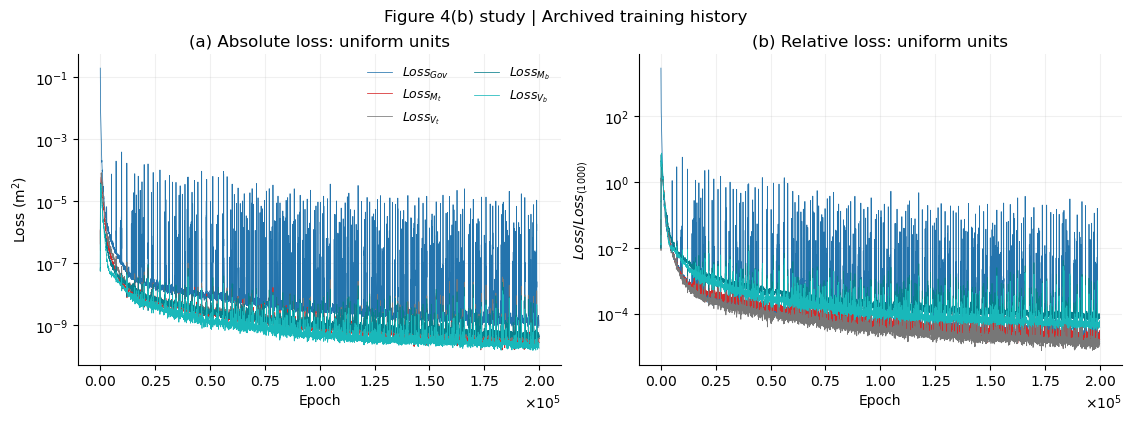

In [5]:
LOSS_LABELS = [r"$Loss_{Gov}$", r"$Loss_{M_t}$", r"$Loss_{V_t}$",
               r"$Loss_{M_b}$", r"$Loss_{V_b}$"]
LOSS_COLORS = ["#2474ad", "#d62728", "#777777", "#087f8c", "#19b8ba"]

def save_figure(fig, stem):
    """Save a high-resolution preview and an editable vector image."""
    fig.savefig(ROOT / "figures" / f"{stem}.png", bbox_inches="tight")
    fig.savefig(ROOT / "figures" / f"{stem}.svg", bbox_inches="tight")

history_fig4 = training_history[training_history.epoch <= 200_000]
fig4, axes = plt.subplots(1, 2, figsize=(11.2, 4.1), layout="constrained")
for name, label, color in zip(LOSS_NAMES, LOSS_LABELS, LOSS_COLORS):
    axes[0].semilogy(history_fig4.epoch, history_fig4[name], label=label,
                     color=color, lw=0.55, rasterized=True)
    baseline = training_history.loc[training_history.epoch == 1000, name]
    if len(baseline) and baseline.iloc[0] > 0:
        axes[1].semilogy(history_fig4.epoch, history_fig4[name] / baseline.iloc[0],
                         color=color, lw=0.55, rasterized=True)

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.18, which="major")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0].set(ylabel=r"Loss (m$^2$)", title="(a) Absolute loss: uniform units")
axes[1].set(ylabel=r"$Loss / Loss_{(1000)}$", title="(b) Relative loss: uniform units")
axes[0].legend(fontsize=9, frameon=False, ncols=2)
if len(history_fig4) < 1000:
    axes[1].text(0.5, 0.5, "Epoch 1000 has not been reached.",
                 ha="center", va="center", transform=axes[1].transAxes)
fig4.suptitle("Figure 4(b) study | " +
              ("Fresh physics-only training" if RUN_MODE == "train" else "Archived training history"))
save_figure(fig4, "figure4_uniform_units")
plt.show()

## 6. Predict pile responses

Recover physical derivatives from normalized depth using $d^jy/dx^j=\alpha^j d^jy/dx_N^j$.

In [6]:
def predict_response(model, case, x=None, n_depths=201):
    """Evaluate a physical pile case; return arrays on CPU in paper units."""
    case.validate()
    x = np.linspace(0.0, case.Lp, n_depths) if x is None else np.asarray(x, dtype=float)
    if x.ndim != 1 or len(x) < 1 or not np.isfinite(x).all():
        raise ValueError("x must be a nonempty, finite, one-dimensional depth array.")
    if x.min() < 0 or x.max() > case.Lp:
        raise ValueError("Prediction depths must lie in [0, Lp].")
    parameter = next(model.parameters())
    with torch.enable_grad():
        xN = torch.tensor(case.alpha * x[:, None], device=parameter.device,
                          dtype=parameter.dtype, requires_grad=True)
        LpN = torch.full_like(xN, case.LpN)
        n = torch.full_like(xN, case.n)
        MtN = case.Mt / (case.EI * case.alpha**2)
        VtN = case.Vt / (case.EI * case.alpha**3)
        yMt_ref, yVt_ref = model(xN, LpN, n)
        y = yMt_ref * (MtN / MtN_ref) + yVt_ref * (VtN / VtN_ref)
        derivatives = depth_derivatives(y, xN, 4)
        scales = [1.0, case.alpha, case.EI * case.alpha**2,
                  case.EI * case.alpha**3, case.EI * case.alpha**4]
        result = {name: (value * scale).detach().cpu().numpy().ravel()
                  for name, value, scale in zip(
                      ("y", "theta", "M", "Fs", "p"), derivatives, scales)}
    result["x"] = x
    result["p_winkler"] = -case.m * x**case.n * result["y"]
    result["governing_residual"] = result["p"] - result["p_winkler"]
    return result

## 7. Figure 9 cases and FEM reference

The reference CSV contains the paper's FEM values for the five parameter sweeps. Predictions are calculated at the depths needed for plotting and comparison.

In [7]:
case_table = pd.read_csv(ROOT / "data" / "figure9_cases.csv")
fem_reference = pd.read_csv(ROOT / "data" / "figure9_fem_reference.csv")
GROUPS = ("loads", "EI", "Lp", "m", "n")
RESPONSES = ("y", "M", "Fs", "p")

def case_from_row(row):
    return PileCase(EI=float(row.EI_kNm2), Lp=float(row.Lp_m),
                    m=float(row.m_kN_per_m_n_plus_2), n=float(row.n),
                    Vt=float(row.Vt_kN), Mt=float(row.Mt_kNm))

cases = {row.case_id: case_from_row(row) for row in case_table.itertuples()}
predictions = {case_id: predict_response(model, case) for case_id, case in cases.items()}
print(f"Loaded {len(cases)} cases and {len(fem_reference)} FEM values.")

Loaded 20 cases and 1360 FEM values.


## 8. Compare PINN and FEM responses

Calculate the overlap ratio $\eta$ and the relative $L_2$ error over the available FEM marker depths. Results are saved in `results/figure9_metrics.csv`.

In [8]:
def curve_metrics(x, prediction, reference):
    """Signed area overlap and relative L2 error for piecewise-linear curves."""
    x, a, b = (np.asarray(v, dtype=float) for v in (x, prediction, reference))
    if len(x) < 2 or not (len(x) == len(a) == len(b)) or np.any(np.diff(x) <= 0):
        raise ValueError("Metrics require matched values at strictly increasing depths.")
    # Add roots of both curves and their difference within each segment.
    refined = list(x)
    for signal in (a, b, a - b):
        for i in np.flatnonzero(signal[:-1] * signal[1:] < 0):
            refined.append(x[i] - signal[i] * (x[i+1] - x[i]) /
                           (signal[i+1] - signal[i]))
    grid = np.unique(refined)
    aa, bb = np.interp(grid, x, a), np.interp(grid, x, b)
    same_sign = aa * bb >= 0
    intersection = np.where(same_sign, np.minimum(abs(aa), abs(bb)), 0.0)
    union = np.where(same_sign, np.maximum(abs(aa), abs(bb)), abs(aa) + abs(bb))
    # np.trapz supports the tested NumPy 1.x environment as well as NumPy 2.x.
    area_int, area_union = np.trapz(intersection, grid), np.trapz(union, grid)
    eta = area_int / area_union if area_union > 0 else 1.0
    dx = np.diff(x)
    def squared_integral(values):
        return np.sum(dx * (values[:-1]**2 + values[:-1]*values[1:] + values[1:]**2) / 3)
    denominator = squared_integral(b)
    error = squared_integral(a - b)
    relative_l2 = np.sqrt(error / denominator) if denominator > 0 else (0.0 if error == 0 else np.inf)
    return float(eta), float(relative_l2)

metric_records = []
for row in case_table.itertuples():
    case = cases[row.case_id]
    for quantity in RESPONSES:
        ref = fem_reference[(fem_reference.case_id == row.case_id) &
                            (fem_reference.quantity == quantity)].sort_values("x_m")
        x = np.clip(ref.x_m.to_numpy(), 0.0, case.Lp)
        prediction = predict_response(model, case, x=x)[quantity]
        eta, relative_l2 = curve_metrics(x, prediction, ref.value.to_numpy())
        metric_records.append({"case_id": row.case_id, "group": row.group,
            "quantity": quantity, "eta": eta, "relative_L2": relative_l2,
            "comparison_x_min_m": x.min(), "comparison_x_max_m": x.max()})
metrics = pd.DataFrame(metric_records)
metrics.to_csv(ROOT / "results" / "figure9_metrics.csv", index=False)
display(metrics.groupby(["group", "quantity"])[["eta", "relative_L2"]]
        .mean().round(4).unstack("quantity"))

prediction_table = pd.concat([
    pd.DataFrame({"case_id": case_id, **response})
    for case_id, response in predictions.items()
], ignore_index=True)
prediction_table.to_csv(ROOT / "results" / "figure9_pinn_predictions.csv", index=False)

eta                         relative_L2                        
quantity      Fs       M       p       y          Fs       M       p       y
group                                                                       
EI        0.9821  0.9921  0.9784  0.9923      0.0192  0.0079  0.0259  0.0069
Lp        0.9569  0.9782  0.9353  0.9680      0.0493  0.0261  0.0823  0.0302
loads     0.9796  0.9960  0.9726  0.9949      0.0209  0.0039  0.0325  0.0040
m         0.9814  0.9920  0.9777  0.9931      0.0199  0.0076  0.0274  0.0063
n         0.9775  0.9931  0.9673  0.9939      0.0239  0.0071  0.0372  0.0052

## 9. Figure 9: PINN and FEM comparison

Each row varies one parameter group. Solid lines show PINN predictions and plus markers show FEM results. The mean overlap ratio is shown in each panel.

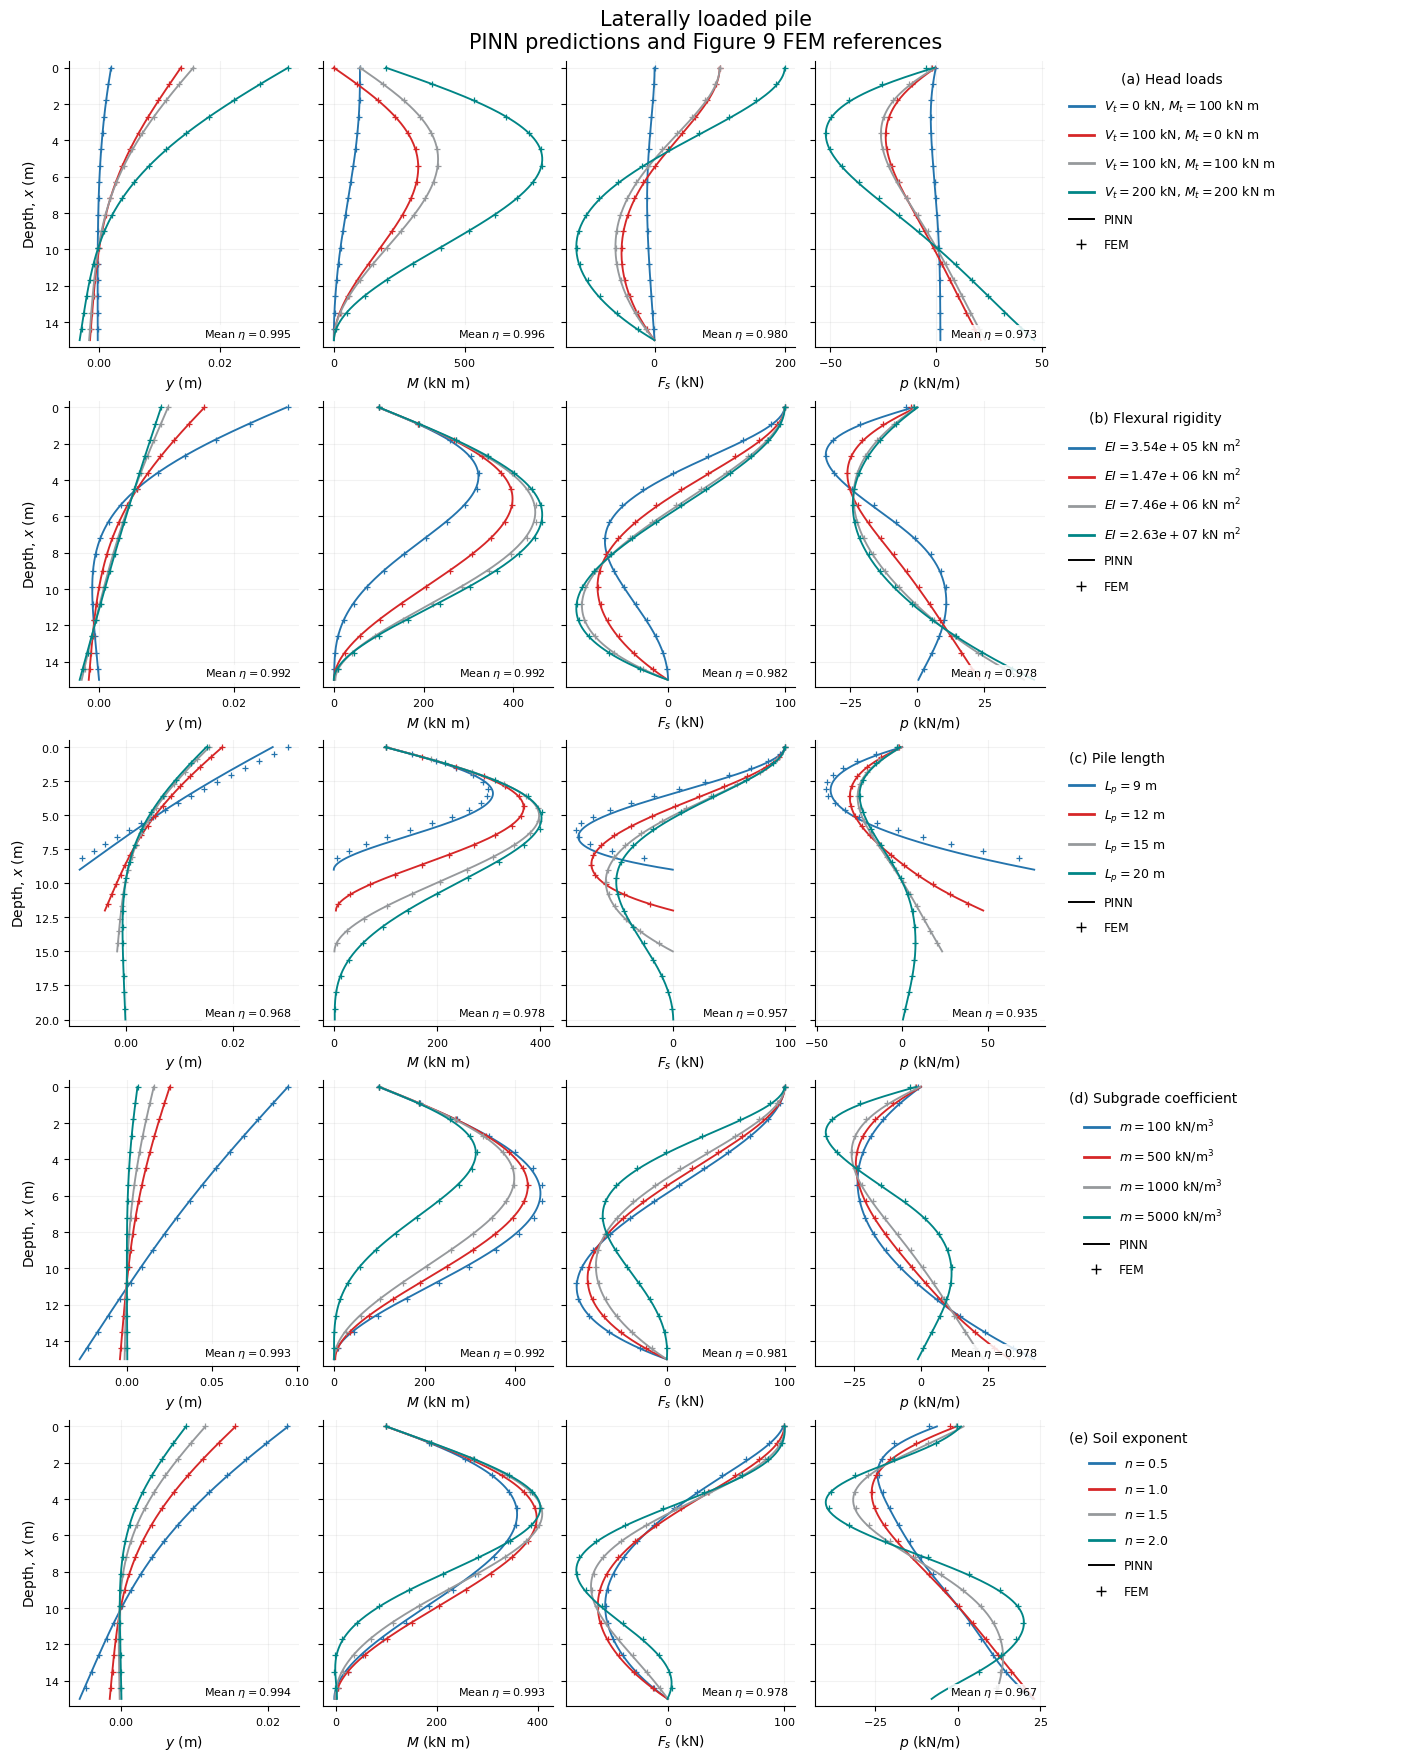

In [9]:
CASE_COLORS = ["#2474ad", "#d62728", "#96999c", "#008586"]
AXIS_LABELS = [r"$y$ (m)", r"$M$ (kN m)", r"$F_s$ (kN)", r"$p$ (kN/m)"]
GROUP_TITLES = {"loads": "Head loads", "EI": "Flexural rigidity",
                "Lp": "Pile length", "m": "Subgrade coefficient", "n": "Soil exponent"}

def case_label(row):
    if row.group == "loads":
        return rf"$V_t={row.Vt_kN:g}$ kN, $M_t={row.Mt_kNm:g}$ kN m"
    if row.group == "EI":
        return rf"$EI={row.EI_kNm2:.3g}$ kN m$^2$"
    if row.group == "Lp":
        return rf"$L_p={row.Lp_m:g}$ m"
    if row.group == "m":
        return rf"$m={row.m_kN_per_m_n_plus_2:g}$ kN/m$^3$"
    return rf"$n={row.n:.1f}$"

fig9 = plt.figure(figsize=(14.0, 17.5), layout="constrained")
grid = fig9.add_gridspec(5, 5, width_ratios=[1, 1, 1, 1, 1.5])
for row_index, group in enumerate(GROUPS):
    rows = case_table[case_table.group == group].sort_values("order")
    maximum_depth = rows.Lp_m.max()
    for col_index, (quantity, xlabel) in enumerate(zip(RESPONSES, AXIS_LABELS)):
        ax = fig9.add_subplot(grid[row_index, col_index])
        for row, color in zip(rows.itertuples(), CASE_COLORS):
            response = predictions[row.case_id]
            ax.plot(response[quantity], response["x"], color=color, lw=1.35)
            ref = fem_reference[(fem_reference.case_id == row.case_id) &
                                (fem_reference.quantity == quantity)]
            ax.plot(ref.value, ref.x_m, linestyle="none", marker="+",
                    color=color, markersize=5, markeredgewidth=0.9)
        ax.set_xlabel(xlabel)
        ax.set_ylim(maximum_depth * 1.025, -maximum_depth * 0.025)
        ax.grid(alpha=0.16)
        if col_index == 0:
            ax.set_ylabel(r"Depth, $x$ (m)")
        else:
            ax.tick_params(labelleft=False)
        subset = metrics[(metrics.group == group) & (metrics.quantity == quantity)]
        ax.text(0.97, 0.035, rf"Mean $\eta={subset.eta.mean():.3f}$",
                transform=ax.transAxes, ha="right", fontsize=8,
                bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 1.5})
        ax.tick_params(axis="both", labelsize=8)
        ax.locator_params(axis="x", nbins=3)
    legend_ax = fig9.add_subplot(grid[row_index, 4])
    legend_ax.axis("off")
    handles = [Line2D([0], [0], color=color, lw=2, label=case_label(row))
               for row, color in zip(rows.itertuples(), CASE_COLORS)]
    handles.extend([
        Line2D([0], [0], color="black", lw=1.4, label="PINN"),
        Line2D([0], [0], color="black", linestyle="none", marker="+",
               markersize=7, label="FEM"),
    ])
    legend_ax.legend(handles=handles, loc="upper left", frameon=False,
                     title=f"({chr(97 + row_index)}) {GROUP_TITLES[group]}",
                     fontsize=9, title_fontsize=10, labelspacing=1.0)

fig9.suptitle("Laterally loaded pile\n"
              "PINN predictions and Figure 9 FEM references", fontsize=15)
save_figure(fig9, "figure9_pinn_fem")
plt.show()